# 01 - Data audit and exploratory analysis (T2, T3, T4)

This notebook looks at the raw file `data/raw/newsgroup_posts.csv` **before** any cleaning. It does three jobs:

- **T2 - data quality audit:** count the problems listed in the *data notes* of the project brief.
- **T3 - exploratory analysis:** class distribution, text length and the most frequent words per class. The charts are saved in `reports/figures/`.
- **T4 - cleaning decisions:** turn what we find into clear rules for the cleaning code (T5). The final rules are in section 10.

It uses the project settings from T1 (`newsclf.config`). The raw file is only read here, never changed.

| Data note in the brief | Section |
|---|---|
| About 500 posts are empty and several hundred texts occur more than once | 3, 4 |
| Texts range from a few words to thousands of words | 5 |
| Posts are informal: typos, code, e-mail addresses, numbers, ASCII art | 6 |
| Several newsgroups are intentionally close | 7 |
| Posts are from the 1990s | 8 |
| Fit TF-IDF on the training data only | 10 |

**Sections:** 1 Setup · 2 First look and class distribution · 3 Empty posts · 4 Duplicates · 5 Text length · 6 Informal content · 7 Frequent words and close newsgroups · 8 Dated vocabulary · 9 Summary of the audit · 10 T4 decision: cleaning rules

**How to read it:** each section starts with the data note it checks, then the code, then the **Findings** and, where something has to be done, a **Decision**.

**How to run it:** install the project once with `pip install -r requirements.txt` (this also installs our own `newsclf` package), then run all cells from top to bottom. Later cells use variables from earlier ones. Whenever a post is printed, e-mail addresses are hidden.

## 1. Setup

In [1]:
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer

# Project settings from T1: seed, file paths and column names
from newsclf.config import FIGURES_DIR, ID_COL, RAW_DATA_PATH, SEED, TARGET_6, TARGET_20, TEXT_COL, set_seed

set_seed()
pd.set_option("display.max_colwidth", 100)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)  # the charts for the report are saved here

raw = pd.read_csv(RAW_DATA_PATH)
print(f"Loaded {len(raw):,} rows and {raw.shape[1]} columns")

# The main numbers of the audit are collected here and shown together in section 9
counts = {"Rows in the raw file": len(raw)}

Loaded 18,846 rows and 4 columns


In [2]:
# An e-mail address looks like name@domain.ending, for example jdoe@cs.example.edu
# (?:\.[\w-]+)+ means "one or more parts such as .example or .edu".
# The ?: makes re.findall return the whole address instead of only the last part.
EMAIL_PATTERN = r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+"


def preview(text, width=70):
    """The start of a post on one line, with e-mail addresses hidden."""
    text = re.sub(EMAIL_PATTERN, "[e-mail]", text)
    text = " ".join(text.split())  # line breaks and repeated spaces become one space
    return text[:width]


preview("Hello,\n\n   please write to jane.doe@example.com   for details.")

'Hello, please write to [e-mail] for details.'

## 2. First look at the file and class distribution

### 2.1 Columns, missing values and labels

In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 18846 entries, 0 to 18845
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   post_id      18846 non-null  int64
 1   text         18331 non-null  str  
 2   newsgroup    18846 non-null  str  
 3   topic_group  18846 non-null  str  
dtypes: int64(1), str(3)
memory usage: 22.0 MB


In [4]:
print("Missing values per column:")
print(raw.isna().sum())
print()
print("Every post_id is unique:", raw[ID_COL].is_unique)
print("Number of newsgroups:   ", raw[TARGET_20].nunique())
print("Number of topic groups: ", raw[TARGET_6].nunique())

# Each newsgroup should belong to exactly one topic group
topics_per_newsgroup = raw.groupby(TARGET_20)[TARGET_6].nunique()
print("Each newsgroup belongs to exactly one topic group:", (topics_per_newsgroup == 1).all())

Missing values per column:
post_id          0
text           515
newsgroup        0
topic_group      0
dtype: int64

Every post_id is unique: True
Number of newsgroups:    20
Number of topic groups:  6
Each newsgroup belongs to exactly one topic group: True


In [5]:
# Five random posts, to see what the data looks like
examples = raw.sample(5, random_state=SEED).copy()
examples[TEXT_COL] = examples[TEXT_COL].fillna("<empty post>").apply(preview)
examples

,post_id,text,newsgroup,topic_group
18265,18266,"The runner can leave his base at any time. If the ball is caught, he's",rec.sport.baseball,recreation
423,424,"Well, it's not an FTP site, but I got an 800 number for Signetics BBS.",sci.electronics,science
7900,7901,"Hi, I was reading through ""The Spaceflight Handbook"" and somewhere in",sci.space,science
14785,14786,"I was a graduate student in the early 1980s, and we had a conference o",talk.politics.misc,politics
5217,5218,"FREE-ENERGY TECHNOLOGY by Robert E. McElwaine, Physicist Ninety to a h",alt.atheism,religion


**Findings.**

- The file has 18,846 rows and the 4 columns described in the brief. Only `text` has missing values (515, see section 3).
- Every `post_id` is unique, so it can identify a post in the split files later (T6).
- Each newsgroup belongs to exactly one topic group, so the two labels never contradict each other. A useful side effect: a split that is stratified by `newsgroup` is automatically stratified by `topic_group` as well.

### 2.2 Posts per class

In [6]:
# Which newsgroups make up each topic group, and how many posts each newsgroup has
raw.groupby([TARGET_6, TARGET_20]).size().to_frame("posts")

posts
topic_group newsgroup                      
comp        comp.graphics               973
            comp.os.ms-windows.misc     985
            comp.sys.ibm.pc.hardware    982
            comp.sys.mac.hardware       963
            comp.windows.x              988
forsale     misc.forsale                975
politics    talk.politics.guns          910
            talk.politics.mideast       940
            talk.politics.misc          775
recreation  rec.autos                   990
            rec.motorcycles             996
            rec.sport.baseball          994
            rec.sport.hockey            999
religion    alt.atheism                 799
            soc.religion.christian      997
            talk.religion.misc          628
science     sci.crypt                   991
            sci.electronics             984
            sci.med                     990
            sci.space                   987

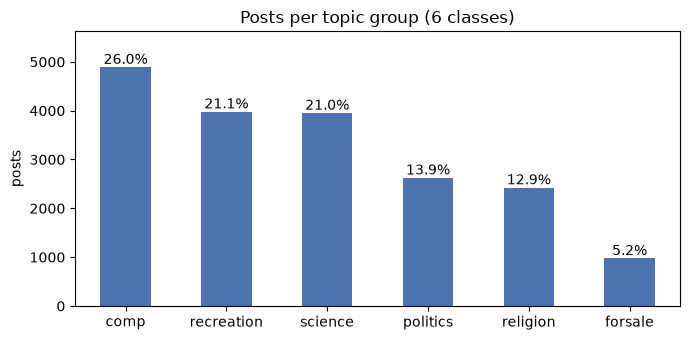

In [7]:
topic_counts = raw[TARGET_6].value_counts()
topic_share = topic_counts / len(raw)

ax = topic_counts.plot(kind="bar", figsize=(7, 3.5), color="#4C72B0", rot=0)
ax.bar_label(ax.containers[0], labels=[f"{share:.1%}" for share in topic_share])  # share on top of each bar
ax.set_ylim(0, topic_counts.max() * 1.15)  # room for the labels
ax.set_xlabel("")
ax.set_ylabel("posts")
ax.set_title("Posts per topic group (6 classes)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "class_distribution_6_topic_groups.png", dpi=150)
plt.show()

Largest newsgroup:  rec.sport.hockey 999
Smallest newsgroup: talk.religion.misc 628
Largest / smallest: 1.59


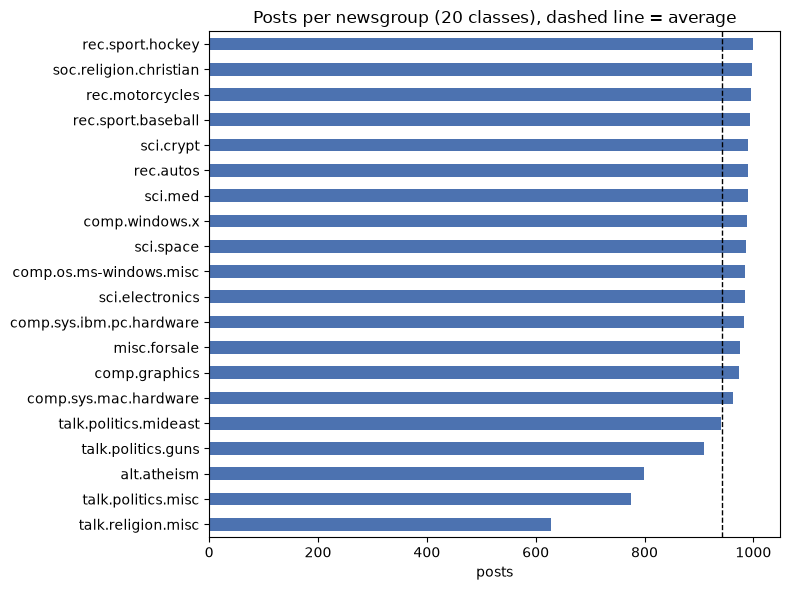

In [8]:
newsgroup_counts = raw[TARGET_20].value_counts()
print("Largest newsgroup: ", newsgroup_counts.idxmax(), newsgroup_counts.max())
print("Smallest newsgroup:", newsgroup_counts.idxmin(), newsgroup_counts.min())
print("Largest / smallest:", round(newsgroup_counts.max() / newsgroup_counts.min(), 2))

ax = newsgroup_counts.sort_values().plot(kind="barh", figsize=(8, 6), color="#4C72B0")
ax.axvline(newsgroup_counts.mean(), color="black", linestyle="--", linewidth=1)
ax.set_xlabel("posts")
ax.set_ylabel("")
ax.set_title("Posts per newsgroup (20 classes), dashed line = average")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "class_distribution_20_newsgroups.png", dpi=150)
plt.show()

**Findings.**

- **The 20 newsgroups are roughly balanced.** The largest (rec.sport.hockey, 999 posts) is only 1.6 times the smallest (talk.religion.misc, 628). Only three groups are clearly below the average: talk.religion.misc (628), talk.politics.misc (775) and alt.atheism (799).
- **The 6 topic groups are not balanced.** `comp` has 26% of the posts because it bundles 5 newsgroups, while `forsale` (1 newsgroup) has only 5.2%. A model could almost ignore `forsale` and still reach a good accuracy. This is why we report **macro-F1** (every class counts the same) and use a **stratified** split.
- **Topic groups follow the subject, not the name.** `talk.religion.misc` belongs to `religion`, not to `politics` like the other `talk.*` groups. The 6-class label must therefore always be read from the `topic_group` column.

## 3. Empty posts

*Data note:* about 500 posts are empty after header removal. Remove them.

In [9]:
missing = raw[TEXT_COL].isna()
is_empty = raw[TEXT_COL].fillna("").str.strip() == ""  # missing, or only spaces and line breaks

print("Missing (NaN):             ", missing.sum())
print("Only spaces or line breaks:", (is_empty & ~missing).sum())
print(f"Empty in total:             {is_empty.sum()} ({is_empty.mean():.1%} of all posts)")
counts["Empty posts"] = int(is_empty.sum())

Missing (NaN):              515
Only spaces or line breaks: 0
Empty in total:             515 (2.7% of all posts)


In [10]:
# Are the empty posts spread evenly over the newsgroups?
empty_per_group = raw.loc[is_empty, TARGET_20].value_counts()
empty_table = pd.DataFrame({
    "empty posts": empty_per_group,
    "% of the newsgroup": (empty_per_group / newsgroup_counts * 100).round(1),
})
empty_table.sort_values("% of the newsgroup", ascending=False)

,empty posts,% of the newsgroup
newsgroup,,
rec.autos,53,5.4
comp.os.ms-windows.misc,38,3.9
rec.sport.baseball,36,3.6
comp.sys.mac.hardware,34,3.5
talk.religion.misc,22,3.5
sci.space,32,3.2
sci.med,30,3.0
sci.crypt,29,2.9
rec.motorcycles,27,2.7


In [11]:
# From here on we only look at the non-empty posts
df = raw[~is_empty].reset_index(drop=True)
print(f"{len(df):,} non-empty posts")

18,331 non-empty posts


**Findings.** 515 posts (2.7%) are empty, all of them stored as missing values (none contain only spaces). Every newsgroup has some empty posts, from 0.6% in comp.windows.x to 5.4% in rec.autos, so removing them changes the class balance only a little.

**Decision:** drop all empty posts. There is nothing to learn from them.

## 4. Duplicates

*Data note:* several hundred texts occur more than once. Remove them, because the same text in the training and the test set makes the results look better than they are.

We compare the texts in two ways:

1. **exact:** only the spaces at the start and the end are removed;
2. **normalised:** in addition, upper/lower case and the number of spaces and line breaks are ignored.

In [12]:
df["text_stripped"] = df[TEXT_COL].str.strip()
df["text_normalised"] = df["text_stripped"].str.lower().str.replace(r"\s+", " ", regex=True)

# duplicated()           -> True for the 2nd, 3rd, ... copy of a text    (sum = extra copies)
# duplicated(keep=False) -> True for every copy, including the first one (sum = rows involved)
for column in ["text_stripped", "text_normalised"]:
    print(column)
    print("   rows that share their text with another row:  ", df[column].duplicated(keep=False).sum())
    print("   extra copies (rows to drop if we keep one copy):", df[column].duplicated().sum())

counts["Exact duplicates (extra copies)"] = int(df["text_stripped"].duplicated().sum())
counts["Duplicates ignoring case and spacing (extra copies)"] = int(df["text_normalised"].duplicated().sum())

text_stripped
   rows that share their text with another row:   131
   extra copies (rows to drop if we keep one copy): 69
text_normalised
   rows that share their text with another row:   149
   extra copies (rows to drop if we keep one copy): 78


In [13]:
# Is the same text sometimes labelled with different newsgroups?
newsgroups_per_text = df.groupby("text_stripped")[TARGET_20].nunique()
conflicting_texts = newsgroups_per_text[newsgroups_per_text > 1].index
print("Texts that appear under more than one newsgroup:", len(conflicting_texts))
counts["Duplicated texts under different newsgroups"] = len(conflicting_texts)
print()

conflicts = df[df["text_stripped"].isin(conflicting_texts)].sort_values("text_stripped")
for group, text in zip(conflicts[TARGET_20], conflicts["text_stripped"]):
    print(f"{group:<25} | {preview(text, 60)}")

Texts that appear under more than one newsgroup: 14

comp.windows.x            | --
comp.sys.mac.hardware     | --
rec.sport.baseball        | ----------
sci.electronics           | ----------
sci.space                 | ----------
sci.electronics           | ----------
soc.religion.christian    | ...
comp.sys.ibm.pc.hardware  | ...
comp.windows.x            | ...
misc.forsale              | Article 10886 of alt.radio.scanner: Path: usenet.ins.cwru.ed
sci.electronics           | Article 10886 of alt.radio.scanner: Path: usenet.ins.cwru.ed
sci.med                   | BIOLOGICAL ALCHEMY ( ANOTHER Form of COLD FUSION ) ( ALTERNA
sci.space                 | BIOLOGICAL ALCHEMY ( ANOTHER Form of COLD FUSION ) ( ALTERNA
comp.os.ms-windows.misc   | CALL FOR PRESENTATIONS NAVY SCIENTIFIC VISUALIZATION AND VIR
comp.graphics             | CALL FOR PRESENTATIONS NAVY SCIENTIFIC VISUALIZATION AND VIR
comp.sys.ibm.pc.hardware  | Could someone please tell me if the 486SLC and 486SLC2 proce
sci.electr

**Findings.**

- Among the 18,331 non-empty posts, 131 rows share their exact text with another row (69 extra copies). Ignoring case and spacing finds a few more: 149 rows and 78 extra copies. The normalised comparison is therefore the better one.
- This is fewer than the "several hundred" of the brief. The brief probably counts the empty posts as well: all 515 of them have the same (empty) text.
- 14 texts appear under **different** newsgroups. Some are junk (`--`, `...`, `----------`, `Hello,`); the others are one post sent to several groups (cross-posts), such as the question about the 486SLC processor in comp.sys.ibm.pc.hardware and sci.electronics. For these texts there is no single correct label.

**Decision:** compare the texts in normalised form; keep one copy of each text; drop **all** copies of a text that appears under more than one newsgroup. Do this **before** the train/validation/test split (T6), so that the same text cannot end up in both the training and the test data.

## 5. Text length

*Data note:* texts range from a few words to thousands. Decide how to handle extremely short and extremely long posts.

We count the words of a post by splitting it at spaces and line breaks.

In [14]:
df["words"] = df[TEXT_COL].str.split().str.len()
df["words"].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(0)

count    18331.0
mean       187.0
std        507.0
min          1.0
1%           4.0
5%          14.0
25%         43.0
50%         86.0
75%        170.0
95%        566.0
99%       1789.0
max      11765.0
Name: words, dtype: float64

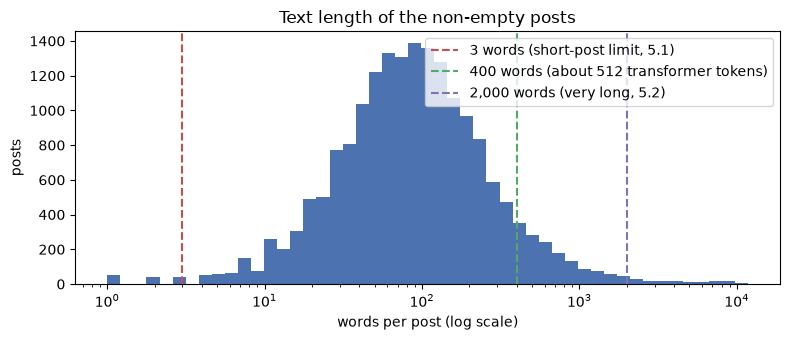

In [15]:
# Most posts are short and a few are huge, so the x-axis uses a log scale (1, 10, 100, 1000, ...).
# np.geomspace makes bins that look equally wide on a log scale.
bins = np.geomspace(1, df["words"].max(), 50)

plt.figure(figsize=(8, 3.5))
plt.hist(df["words"], bins=bins, color="#4C72B0")
plt.axvline(3, color="#C44E52", linestyle="--", label="3 words (short-post limit, 5.1)")
plt.axvline(400, color="#55A868", linestyle="--", label="400 words (about 512 transformer tokens)")
plt.axvline(2000, color="#8172B3", linestyle="--", label="2,000 words (very long, 5.2)")
plt.xscale("log")
plt.xlabel("words per post (log scale)")
plt.ylabel("posts")
plt.title("Text length of the non-empty posts")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "text_length_histogram.png", dpi=150)
plt.show()

**Findings.** The lengths are very skewed: the median post has 86 words, the mean 187, and half of the posts have between 43 and 170 words. A few posts are very long (the longest has 11,765 words) and pull the mean up. Both ends are examined below.

### 5.1 Very short posts

In [16]:
for limit in [2, 3, 5, 10]:
    n_posts = (df["words"] < limit).sum()
    print(f"Posts with fewer than {limit:>2} words: {n_posts:>4} ({n_posts / len(df):.1%})")

Posts with fewer than  2 words:   52 (0.3%)
Posts with fewer than  3 words:   91 (0.5%)
Posts with fewer than  5 words:  187 (1.0%)
Posts with fewer than 10 words:  539 (2.9%)


In [17]:
short_posts = df[df["words"] < 5]
no_letter = ~short_posts[TEXT_COL].str.contains("[A-Za-z]")
print("Posts with fewer than 5 words that contain no letter at all:", no_letter.sum())
print()

# 20 random posts with fewer than 5 words, sorted by their length
sample = short_posts.sample(20, random_state=SEED).sort_values("words")
for n_words, group, text in zip(sample["words"], sample[TARGET_20], sample[TEXT_COL]):
    print(f"{n_words} words | {group:<25} | {preview(text, 50)}")

Posts with fewer than 5 words that contain no letter at all: 20

1 words | rec.motorcycles           | Yep.
1 words | comp.windows.x            | ...
1 words | comp.graphics             | Keywords:
1 words | talk.religion.misc        | critus
1 words | comp.graphics             | Hello,
1 words | rec.autos                 | ~~15
2 words | talk.politics.guns        | Religious fanaticism?
2 words | sci.electronics           | try sci.energy
2 words | sci.electronics           | ISBN 0-13-747270-6
2 words | misc.forsale              | Simple, eh?
2 words | rec.sport.hockey          | Whatta ass!!!!!
3 words | talk.politics.mideast     | Dear Mr. Davidsson,
3 words | rec.motorcycles           | Squeaky BMW riders.
3 words | rec.motorcycles           | Ditto for me..
3 words | rec.motorcycles           | Cam chain. -Mike
4 words | rec.sport.hockey          | Vielen dank Desperate Fan
4 words | talk.politics.mideast     | What are you, retarded?
4 words | comp.windows.x            | X Resou

**Findings.**

- Very short posts are rare: 187 posts (1.0%) have fewer than 5 words, and 20 of them contain no letter at all (for example `...` or `~~15`).
- Posts with **1 or 2 words** almost never say anything about the topic: `Yep.`, `Hello,`, `Keywords:`, `Simple, eh?`, `try sci.energy`. Some are even misleading: `Religious fanaticism?` is labelled talk.politics.guns.
- Posts with **3 or 4 words** sometimes do name their topic: `Squeaky BMW riders.` and `Cam chain. -Mike` (rec.motorcycles), `X Resource, Issue 6` (comp.windows.x), `1B Career: DON MATTINGLY` (rec.sport.baseball).

**Decision:** drop posts with **fewer than 3 words**. This removes the fragments without content and keeps the short posts that still name their topic. It concerns only about half a percent of the posts (exact number in the first cell of 5.1), so the class balance does not change. In T5 the words are counted **after** the other cleaning steps, because removing noise lines (section 6.3) can make a post shorter.

### 5.2 Very long posts

In [18]:
very_long = df[df["words"] > 2000]
print(f"Posts with more than 2,000 words: {len(very_long)} ({len(very_long) / len(df):.1%})")
print(very_long[TARGET_20].value_counts().head(8))
print()

print("The 10 longest posts:")
longest = df.sort_values("words", ascending=False).head(10)
for n_words, group, text in zip(longest["words"], longest[TARGET_20], longest[TEXT_COL]):
    print(f"{n_words:>6,} words | {group:<25} | {preview(text, 55)}")
print()

over_400 = (df["words"] > 400).mean()
print(f"Posts with more than 400 words (a 512-token transformer would cut them): {over_400:.1%}")

Posts with more than 2,000 words: 150 (0.8%)
newsgroup
talk.politics.mideast     24
comp.windows.x            18
sci.med                   16
talk.politics.misc        14
sci.crypt                 10
comp.graphics             10
soc.religion.christian     9
sci.space                  9
Name: count, dtype: int64

The 10 longest posts:
11,765 words | sci.electronics           | Since electrical wiring questions do turn up from time 
11,251 words | rec.sport.hockey          | Archive-name: hockey-faq rec.sport.hockey answers to Fr
11,198 words | talk.politics.mideast     | Accounts of Anti-Armenian Human Right Violations in Aze
10,297 words | talk.politics.mideast     | Accounts of Anti-Armenian Human Rights Violations in Az
 9,507 words | talk.politics.mideast     | Accounts of Anti-Armenian Human Right Violations in Aze
 9,365 words | comp.windows.x            | Archive-name: Xt-FAQ Version: $Id: FAQ-Xt,v 1.28 93/04/
 9,196 words | comp.graphics             | Archive-name: jpeg-faq Last

**Findings.**

- 150 posts (0.8%) have more than 2,000 words, most of them in talk.politics.mideast (24), comp.windows.x (18) and sci.med (16). The longest ones are FAQs (hockey FAQ, Xt FAQ, JPEG FAQ), technical guides and long reports. They are full of topic words, so they are useful, not noise.
- **Near-duplicates:** the JPEG FAQ appears three times, as versions from 18 April, 2 May and 16 May 1993. The texts differ in a few places, so the exact duplicate check of section 4 does not find them. If one version is in the training set and another in the test set, the test score is a little too optimistic. Bonus task B5 (near-duplicate check) can measure this.
- TF-IDF has no length limit and scales every post vector to length 1, so a long post does not count more than a short one. A transformer, in contrast, reads at most 512 tokens (about 400 words). For the posts above that limit (more than 5% of the posts, because the 95th percentile is 566 words) it only sees the beginning.

**Decision:** keep all long posts and do not cut them in the cleaning step. For the transformer models (T10, T11) the tokenizer truncates them to the model's maximum length; we mention this as a limitation.

### 5.3 Does the typical length differ between newsgroups?

In [19]:
# Quartiles of the post length per newsgroup, sorted by the median (50%)
length_per_group = df.groupby(TARGET_20)["words"].describe()[["25%", "50%", "75%"]]
length_per_group.sort_values("50%")

,25%,50%,75%
newsgroup,,,
rec.motorcycles,31.0,62.0,129.00
comp.graphics,37.0,66.0,124.50
misc.forsale,34.0,66.0,113.50
comp.os.ms-windows.misc,39.0,71.0,129.00
rec.sport.baseball,35.0,72.0,152.75
comp.sys.mac.hardware,41.0,73.0,123.00
rec.autos,40.0,76.0,136.00
comp.windows.x,42.0,80.0,154.75
comp.sys.ibm.pc.hardware,45.0,81.0,142.00


**Findings.** The median length goes from 62 words (rec.motorcycles) to 158 words (soc.religion.christian): the discussion groups about religion and politics have longer posts than the motorcycle, graphics and for-sale groups. But the middle halves of the newsgroups overlap a lot (for example 31 to 129 words in rec.motorcycles and 76 to 352 words in soc.religion.christian). The length alone cannot tell the newsgroups apart; the words have to do that.

## 6. Informal content

*Data note:* posts are informal (typos, code snippets, e-mail addresses, numbers, ASCII art). Cleaning must be careful, because over-cleaning removes signal.

For every kind of content we ask two questions: **how often does it occur**, and **does it tell us something about the topic**? If yes, we keep it; if not, it is a candidate for cleaning.

### 6.1 E-mail addresses and URLs

In [20]:
# One row per (post, address). The set keeps each address only once per post.
rows = []
for post_id, group, text in zip(df[ID_COL], df[TARGET_20], df[TEXT_COL]):
    for address in set(re.findall(EMAIL_PATTERN, text.lower())):
        rows.append((post_id, group, address))
emails = pd.DataFrame(rows, columns=[ID_COL, TARGET_20, "address"])

has_email = df[ID_COL].isin(emails[ID_COL])  # True/False for every post
print(f"Posts with an e-mail address: {has_email.sum():,} ({has_email.mean():.0%})")
print(f"Different addresses:          {emails['address'].nunique():,}")
counts["Posts with an e-mail address"] = int(has_email.sum())

Posts with an e-mail address: 2,798 (15%)
Different addresses:          4,211


In [21]:
# Do the same addresses come back, and do they stay in one newsgroup?
# crosstab: one row per address, one column per newsgroup, value = number of posts
address_table = pd.crosstab(emails["address"], emails[TARGET_20])
posts_per_address = address_table.sum(axis=1)
share_in_main_group = address_table.max(axis=1) / posts_per_address

frequent = posts_per_address >= 3
print("Addresses found in 3 or more posts:", frequent.sum())
print(f"Of those, addresses with at least 90% of their posts in one newsgroup: "
      f"{(share_in_main_group[frequent] >= 0.9).mean():.0%}")

Addresses found in 3 or more posts: 294
Of those, addresses with at least 90% of their posts in one newsgroup: 74%


In [22]:
has_url = df[TEXT_COL].str.contains(r"https?://|www\.|ftp\.")
print(f"Posts with a URL or FTP host: {has_url.sum()} ({has_url.mean():.1%})")
counts["Posts with a URL or FTP host"] = int(has_url.sum())

Posts with a URL or FTP host: 121 (0.7%)


**Findings.**

- 2,798 posts (15%) contain an e-mail address, with 4,211 different addresses.
- People who post often usually stay in one newsgroup. We looked at the 294 addresses that appear in 3 or more posts. For 74% of them (about 218 addresses), all or almost all of their posts (at least 90%) are in the same newsgroup. For example, an address that appears in 5 posts has all 5 in rec.motorcycles.
- This is a problem. The tokenizer splits an address into words such as jdoe, cs, example, edu (see 6.4), so the model sees the address like any other word. It can learn a shortcut: "posts that contain jdoe belong to rec.motorcycles". This rule is about the person who wrote the post, not about what the post says.
   - The test score would be too high: the same people have posts in both the training and the test set. Some test posts would be classified correctly only because the model recognises the author.
   - The shortcut does not work in real use: a text pasted into the UI is written by a new person whose address the model has never seen.
- But an address can still be a fair hint. misc.forsale has the most addresses (26% of its posts, see 6.5), because sellers write "contact me at …". The presence of an address says something about the topic; whose address it is does not.
- URLs are rare: 121 posts (under 1%).

**Decision:** replace every e-mail address with the single word `emailaddress` and every URL with `urladdress`. This removes the author but keeps the hint "an address was here". The placeholder must be one word (see 6.4). Replace the e-mail addresses first: an address such as `name@ftp.example.edu` contains `ftp.` and would otherwise be cut apart by the URL rule.

### 6.2 Numbers and code snippets

For every number with 2 to 4 digits we count in how many posts it appears (once per post) and which share of these posts is in the number's most common newsgroup. A number without topic meaning would be spread over all 20 newsgroups, so its share would be around 1/20 = 0.05.

In [23]:
rows = []
for group, text in zip(df[TARGET_20], df[TEXT_COL]):
    for number in set(re.findall(r"\b\d{2,4}\b", text)):  # set: each number once per post
        rows.append((group, number))
numbers = pd.DataFrame(rows, columns=[TARGET_20, "number"])

# One row per number, one column per newsgroup, value = number of posts
number_table = pd.crosstab(numbers["number"], numbers[TARGET_20])
number_table = number_table[number_table.sum(axis=1) >= 40]  # only numbers found in 40 or more posts

number_summary = pd.DataFrame({
    "posts": number_table.sum(axis=1),
    "main newsgroup": number_table.idxmax(axis=1),
    "share in main newsgroup": (number_table.max(axis=1) / number_table.sum(axis=1)).round(2),
})
number_summary.sort_values("share in main newsgroup", ascending=False).head(10)

,posts,main newsgroup,share in main newsgroup
number,,,
1914,53,talk.politics.mideast,0.94
1948,42,talk.politics.mideast,0.83
610,48,comp.sys.mac.hardware,0.83
1920,58,talk.politics.mideast,0.78
1967,57,talk.politics.mideast,0.68
950,47,comp.sys.mac.hardware,0.47
1974,47,talk.politics.mideast,0.47
486,196,comp.sys.ibm.pc.hardware,0.45
230,62,comp.sys.mac.hardware,0.42


In [24]:
has_xt_code = df[TEXT_COL].str.contains(r"\bXt[A-Z]\w+")  # X toolkit calls such as XtAppMainLoop
has_c_include = df[TEXT_COL].str.contains("#include", regex=False)  # lines of C code

print("Posts with X toolkit calls (Xt...):", has_xt_code.sum())
print(df.loc[has_xt_code, TARGET_20].value_counts())
print()
print("Posts with C '#include' lines:", has_c_include.sum())
print(df.loc[has_c_include, TARGET_20].value_counts().head(3))
counts["Posts with X toolkit code"] = int(has_xt_code.sum())

Posts with X toolkit calls (Xt...): 60
newsgroup
comp.windows.x    60
Name: count, dtype: int64

Posts with C '#include' lines: 45
newsgroup
comp.windows.x              28
comp.sys.ibm.pc.hardware     7
comp.graphics                3
Name: count, dtype: int64


**Findings.**

- Many numbers are topic words: years such as 1914, 1920 and 1948 point to talk.politics.mideast, 610 to comp.sys.mac.hardware, and 486 (the Intel processor) to comp.sys.ibm.pc.hardware. Their shares (0.39 to 0.94) are far above the 0.05 of a number without topic meaning.
- Code is topical too: all 60 posts with X toolkit calls are in comp.windows.x, and so are 28 of the 45 posts with `#include` lines.

**Decision:** keep numbers and code.

### 6.3 Reply quotes, encoded files and separator lines

These are easiest to find **line by line**. Each rule below is a small function that looks at one line and returns `True` or `False`:

- **quote line:** starts with `>`. It is text from another post, quoted in a reply. 
- **encoded line:** one line of a file that was put into the post as text (uuencode, base64, PGP keys). It looks like random characters.
- **separator line:** at least 4 characters and no letter or digit, such as `------` or `******` (also simple ASCII art).

In [25]:
def is_quote_line(line):
    """A reply quote: the first visible character is '>'."""
    return line.strip().startswith(">")


def is_encoded_line(line):
    """A rough rule for the two usual ways to put a file into a post:
    - uuencode: starts with 'M', 56 to 62 characters, no spaces and no lower-case letters
    - base64 (also PGP keys): 60 to 76 letters, digits, '+' or '/', maybe '=' at the end
    """
    line = line.strip()
    uuencode = (line.startswith("M") and 56 <= len(line) <= 62
                and " " not in line and not any(ch.islower() for ch in line))
    body = line.rstrip("=")  # the '=' at the end of a base64 line is only padding
    base64 = 60 <= len(body) <= 76 and all(ch.isalnum() or ch in "+/" for ch in body)
    return uuencode or base64


def is_separator_line(line):
    """At least 4 characters and no letter or digit, such as ------ or ******."""
    line = line.strip()
    return len(line) >= 4 and not any(ch.isalnum() for ch in line)


def count_lines(text, rule):
    """Number of lines in a post for which rule(line) is True (True counts as 1)."""
    return sum(rule(line) for line in text.splitlines())

In [26]:
quote_lines = df[TEXT_COL].apply(lambda text: count_lines(text, is_quote_line))
encoded_lines = df[TEXT_COL].apply(lambda text: count_lines(text, is_encoded_line))
separator_lines = df[TEXT_COL].apply(lambda text: count_lines(text, is_separator_line))
has_non_ascii = df[TEXT_COL].apply(lambda text: not text.isascii())

print("Posts with reply-quote lines:   ", (quote_lines > 0).sum())
print("Posts with encoded-file lines:  ", (encoded_lines > 0).sum(), f"({encoded_lines.sum():,} lines in total)")
print("Posts with separator lines:     ", (separator_lines > 0).sum())
print("Posts with non-ASCII characters:", has_non_ascii.sum())

counts["Posts with leftover reply quotes"] = int((quote_lines > 0).sum())
counts["Posts with encoded files"] = int((encoded_lines > 0).sum())
counts["Posts with separator or ASCII-art lines"] = int((separator_lines > 0).sum())
counts["Posts with non-ASCII characters"] = int(has_non_ascii.sum())

Posts with reply-quote lines:    181
Posts with encoded-file lines:   31 (15,397 lines in total)
Posts with separator lines:      2170
Posts with non-ASCII characters: 25


In [27]:
# Check the rules by eye: for each rule, the first matching line in 5 random posts
shuffled_texts = df[TEXT_COL].sample(frac=1, random_state=SEED)

for name, rule in [("quote", is_quote_line), ("encoded", is_encoded_line), ("separator", is_separator_line)]:
    print(f"Lines found by the {name} rule:")
    shown = 0
    for text in shuffled_texts:
        matching_lines = [line for line in text.splitlines() if rule(line)]
        if matching_lines:
            print("   ", preview(matching_lines[0], 70))
            shown += 1
        if shown == 5:
            break
    print()

Lines found by the quote rule:
    >>I see you are a total ignorant asshole as well.
    > Lines: 13
    >No, I am _not_ neglecting that, I'm merely asking you whether the exi
    > unsealed, it is CLEAR that Clinton and Reno supported an
    >

Lines found by the encoded rule:
    ///////////////////////////////////////////////////////////////
    MR1865%22DM75U=75U4)"0IV=G9V=G9V=G9V=G9V=G9V=G9V=G9V=G9V=G9V=
    M[H^.O<>Q;SIV'\>.[-A_'/N=8P]R[(-6W@"C''N?8Y=R[%>.G<JQ]SCV*G>I
    M)G(F&G*Z<G*R)G(:NB8:NAHFNAJZ<AHF<AJZ)AH:&K*R&B9R)G(F&KHF&AJZ
    MAZ)75U=7R!1KP"5A8=F>`7;UG)\&V0&>*YZ>*W5&$'Z]M;T0AX>'AX>'AX>'

Lines found by the separator rule:
    ------------------------------------------------------------------
    ----------------------------------------------------------------------
    : --
    ----------
    ---------------------------------------------



In [28]:
print("Newsgroups of the posts with encoded files:")
print(df.loc[encoded_lines > 0, TARGET_20].value_counts())

Newsgroups of the posts with encoded files:
newsgroup
comp.os.ms-windows.misc    18
sci.crypt                   5
comp.windows.x              2
talk.politics.guns          2
misc.forsale                1
comp.sys.mac.hardware       1
sci.electronics             1
alt.atheism                 1
Name: count, dtype: int64


**Findings.**

- **Reply quotes:** 181 posts (1%) still contain quoted lines. Quoted text was written by someone else, often in another post of the data set, so it is not the post's own content.
- **Encoded files:** only 31 posts, but together 15,397 lines of random-looking characters, mostly uuencoded programs in comp.os.ms-windows.misc (18 posts) and PGP keys in sci.crypt (5 posts). If we feed this data into the model, the tokenizer would turn each of these lines into "words" that occur nowhere else. 
- **Separator lines and ASCII art:** 2,170 posts (12%). They contain no words.
- **Non-ASCII characters** (25 posts) and **typos** are rare and not systematic. Spelling correction would be slow and could "correct" technical words such as `Xt` or `SIMM`.

**Decision:** in every post, remove the reply-quote lines, the encoded-file lines and the separator lines. Leave non-ASCII characters and typos as they are.

### 6.4 What does the TF-IDF tokenizer keep?

Before deciding what to clean, it helps to see what the model will actually get. `TfidfVectorizer` lower-cases a text and splits it into tokens. By default a token is 2 or more letters, digits or underscores in a row, and everything else is thrown away. Below, the same default tokenizer reads a made-up post with the kinds of informal content found above.

In [29]:
tokenizer = CountVectorizer().build_analyzer()  # the same default tokenizer as in TfidfVectorizer

example_post = """Mail me at jdoe@cs.example.edu or see ftp.example.com/pub
----------------------------------------
I have a 486DX2 with 8 MB RAM :-)  XtAppMainLoop(app);
________________________________________"""

print(tokenizer(example_post))
print(tokenizer("[e-mail]"), tokenizer("emailaddress"))

['mail', 'me', 'at', 'jdoe', 'cs', 'example', 'edu', 'or', 'see', 'ftp', 'example', 'com', 'pub', 'have', '486dx2', 'with', 'mb', 'ram', 'xtappmainloop', 'app', '________________________________________']
['mail'] ['emailaddress']


**Findings.**

- Separator lines, smileys and single characters (`I`, `a`, `8`) disappear by themselves. Only the line of underscores survives, as one long "word", because the tokenizer treats `_` like a letter.
- An e-mail address is cut into its parts (`jdoe`, `cs`, `example`, `edu`), so the model would see the poster's name and university: the author signal from 6.1.
- Numbers with 2 or more characters (`486dx2`) and code names (`xtappmainloop`) are kept: the topic signal from 6.2 survives without extra work.
- A placeholder must be one word: `[e-mail]` becomes `mail`, while `emailaddress` stays one token.
- The vectorizer already lower-cases the text and ignores punctuation, so the cleaning step does not need to do this.

### 6.5 Overview: which newsgroups contain which informal content?

One row per newsgroup, one column per kind of content. Each cell is the percentage of the newsgroup's posts that contain it.

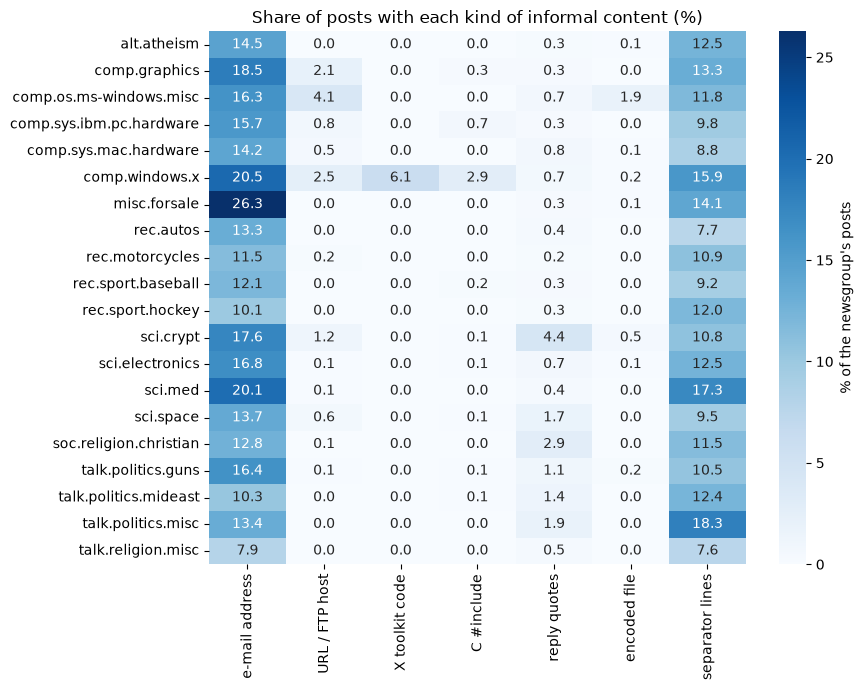

In [30]:
# One True/False column per kind of content, one row per post.
# The mean of a True/False column is the share of True values, so mean * 100 = percent of posts.
flags = pd.DataFrame({
    "e-mail address": has_email,
    "URL / FTP host": has_url,
    "X toolkit code": has_xt_code,
    "C #include": has_c_include,
    "reply quotes": quote_lines > 0,
    "encoded file": encoded_lines > 0,
    "separator lines": separator_lines > 0,
})
percent_per_group = flags.groupby(df[TARGET_20]).mean() * 100

plt.figure(figsize=(9, 7))
sns.heatmap(percent_per_group, annot=True, fmt=".1f", cmap="Blues", xticklabels=True, yticklabels=True,
            cbar_kws={"label": "% of the newsgroup's posts"})
plt.title("Share of posts with each kind of informal content (%)")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.show()

**Findings.**

- E-mail addresses and separator lines occur in every newsgroup (roughly 8% to 26% of the posts), so on their own they say little about the topic. The exception is misc.forsale with the most addresses (26%), because sellers give an address for contact.
- Code is concentrated: X toolkit calls only in comp.windows.x, and `#include` lines mostly there too. URLs are mostly in the comp groups and sci.crypt, encoded files in a few computer and crypto groups.
- Reply quotes are most common in sci.crypt (4.4%) and soc.religion.christian (2.9%).


## 7. Most frequent words and close newsgroups

*Data note:* several groups are intentionally close (for example comp.sys.ibm.pc.hardware vs comp.sys.mac.hardware, talk.politics.guns vs talk.politics.misc), so perfect accuracy is not possible.

We first look at the most frequent words of each class (T3), then compare the word lists of the newsgroups. A word is counted **once per post**, so we count in how many posts it appears. Only words with 3 or more letters are used, and English stop words such as *the* or *and* are left out.

In [31]:
def count_words(texts):
    """For every word: in how many of the texts it appears (3+ letters, no stop words)."""
    word_counter = Counter()
    for text in texts:
        words_in_text = set(re.findall(r"[a-z]{3,}", text.lower())) - ENGLISH_STOP_WORDS
        word_counter.update(sorted(words_in_text))  # sorted: ties come out in the same order in every run
    return word_counter


def top_words(texts, n=30):
    """The n words that appear in the most texts."""
    return [word for word, n_texts in count_words(texts).most_common(n)]


newsgroups = sorted(df[TARGET_20].unique())
top_by_group = {}
for group in newsgroups:
    top_by_group[group] = top_words(df.loc[df[TARGET_20] == group, TEXT_COL])

# A word in the top 30 of 10 or more newsgroups is a general forum word: it says nothing about the topic.
# (TF-IDF follows the same idea: a word that appears in many posts gets a low weight.)
appearances = Counter()
for words in top_by_group.values():
    appearances.update(words)
general_words = {word for word, n_groups in appearances.items() if n_groups >= 10}
print("General forum words:", ", ".join(sorted(general_words)))

General forum words: did, does, don, good, just, know, like, make, new, people, think, time, use, used, want, way


### 7.1 Most frequent words per class

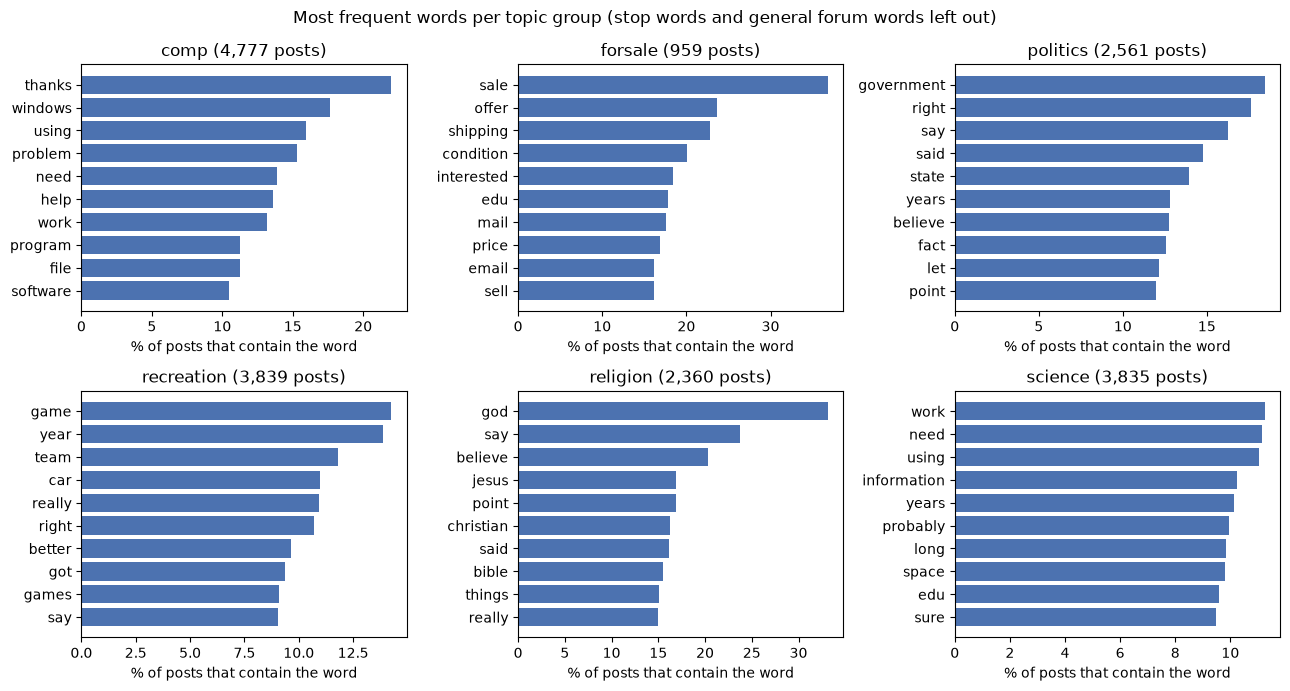

In [32]:
# Top 10 words of each topic group, general forum words left out (chart saved for the report)
topics = sorted(df[TARGET_6].unique())
fig, axes = plt.subplots(2, 3, figsize=(13, 7))

for ax, topic in zip(axes.flatten(), topics):
    texts = df.loc[df[TARGET_6] == topic, TEXT_COL]
    word_counts = count_words(texts)
    top = [(word, n) for word, n in word_counts.most_common(40) if word not in general_words][:10]
    words = [word for word, n in top]
    percent = [n / len(texts) * 100 for word, n in top]
    ax.barh(words[::-1], percent[::-1], color="#4C72B0")  # reversed: most frequent word at the top
    ax.set_title(f"{topic} ({len(texts):,} posts)")
    ax.set_xlabel("% of posts that contain the word")

plt.suptitle("Most frequent words per topic group (stop words and general forum words left out)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "top_words_per_topic_group.png", dpi=150)
plt.show()

In [33]:
# The same for the 20 newsgroups, as a table: the 8 most frequent topic words of each newsgroup
top_words_table = {}
for group in newsgroups:
    topic_words = [word for word in top_by_group[group] if word not in general_words]
    top_words_table[group] = ", ".join(topic_words[:8])
pd.Series(top_words_table).to_frame("most frequent words (general forum words left out)")

,most frequent words (general forum words left out)
alt.atheism,"say, god, believe, said, religion, point, really, right"
comp.graphics,"graphics, thanks, need, program, image, help, file, using"
comp.os.ms-windows.misc,"windows, dos, thanks, file, using, problem, win, files"
comp.sys.ibm.pc.hardware,"thanks, drive, card, problem, help, need, work, using"
comp.sys.mac.hardware,"mac, apple, thanks, drive, problem, work, need, monitor"
comp.windows.x,"window, thanks, using, problem, help, server, windows, running"
misc.forsale,"sale, offer, shipping, condition, interested, edu, mail, price"
rec.autos,"car, cars, engine, right, problem, really, drive, year"
rec.motorcycles,"bike, dod, ride, right, riding, really, got, bikes"
rec.sport.baseball,"year, game, baseball, team, games, better, hit, players"


**Findings.**

- Once stop words and general forum words are removed, each list is easy to match with its class: for example selling words for `forsale`, *god* for `religion`, and hardware and software words for `comp`. This is the vocabulary a TF-IDF model will learn from.
- Topic groups that bundle several newsgroups (`comp`, `science`, `recreation`) mix the vocabularies of their newsgroups, while `forsale` consists of a single newsgroup.
- In the 20-newsgroup table, newsgroups of the same topic group share several of their top words. Section 7.2 measures this.

### 7.2 Which newsgroups use the same words?

For each pair of newsgroups we count how many of their top-30 words they share (general forum words left out). The newsgroups are ordered by topic group, so that groups of the same topic sit next to each other.

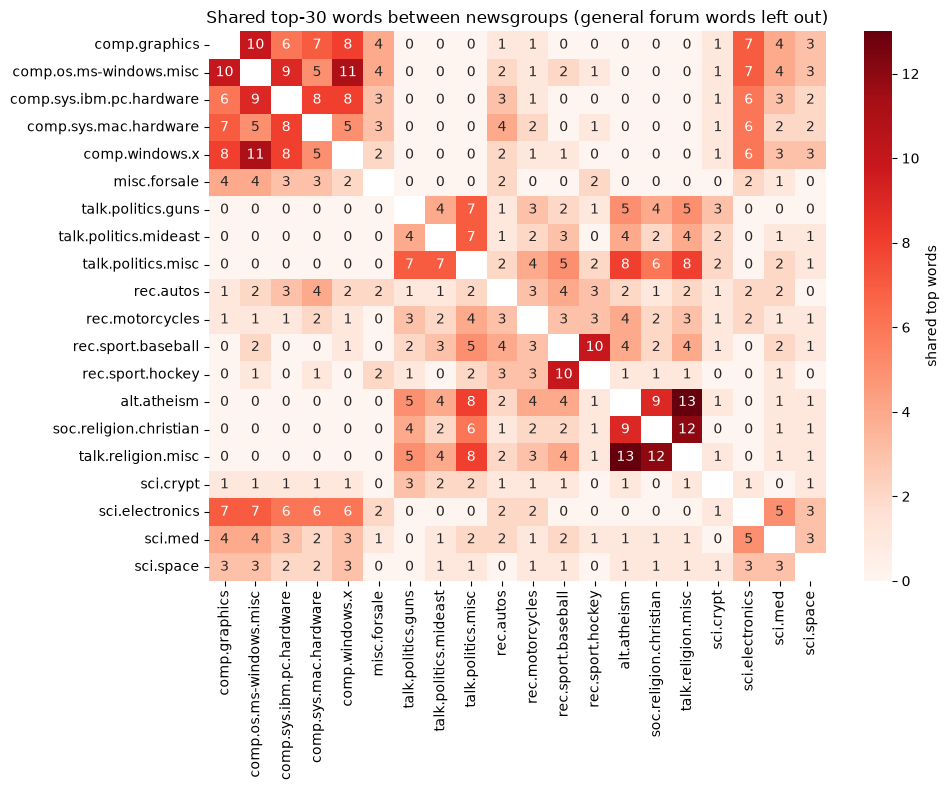

In [34]:
order = raw.drop_duplicates(TARGET_20).sort_values([TARGET_6, TARGET_20])[TARGET_20].tolist()

shared_counts = pd.DataFrame(np.nan, index=order, columns=order)  # the diagonal stays empty
for group_a in order:
    for group_b in order:
        if group_a != group_b:
            shared = set(top_by_group[group_a]) & set(top_by_group[group_b])
            shared_counts.loc[group_a, group_b] = len(shared - general_words)

plt.figure(figsize=(10, 8))
sns.heatmap(shared_counts, annot=True, fmt=".0f", cmap="Reds", xticklabels=True, yticklabels=True,
            cbar_kws={"label": "shared top words"})
plt.title("Shared top-30 words between newsgroups (general forum words left out)")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "shared_top_words_newsgroups.png", dpi=150)
plt.show()

In [35]:
pairs = [
    ("comp.sys.ibm.pc.hardware", "comp.sys.mac.hardware"),  # named in the brief
    ("talk.politics.guns", "talk.politics.misc"),  # named in the brief
    ("alt.atheism", "talk.religion.misc"),  # same topic group (religion)
    ("sci.electronics", "comp.sys.ibm.pc.hardware"),  # different topic groups (science and comp)
    ("rec.sport.hockey", "sci.med"),  # far apart, for comparison
]
for group_a, group_b in pairs:
    shared = (set(top_by_group[group_a]) & set(top_by_group[group_b])) - general_words
    print(f"{group_a} vs {group_b}: {len(shared)} shared top words")
    print("   ", ", ".join(sorted(shared)))

comp.sys.ibm.pc.hardware vs comp.sys.mac.hardware: 8 shared top words
    computer, drive, need, problem, scsi, thanks, using, work
talk.politics.guns vs talk.politics.misc: 7 shared top words
    believe, going, government, point, right, said, say
alt.atheism vs talk.religion.misc: 13 shared top words
    believe, doesn, fact, god, point, read, really, religion, right, said, say, things, true
sci.electronics vs comp.sys.ibm.pc.hardware: 6 shared top words
    help, need, problem, thanks, using, work
rec.sport.hockey vs sci.med: 1 shared top words
    really


In [36]:
# What separates the two hardware groups?
ibm = top_by_group["comp.sys.ibm.pc.hardware"]
mac = top_by_group["comp.sys.mac.hardware"]
print("Only in the IBM PC top 30:", [word for word in ibm if word not in mac and word not in general_words])
print("Only in the Mac top 30:   ", [word for word in mac if word not in ibm and word not in general_words])

Only in the IBM PC top 30: ['card', 'help', 'controller', 'bus', 'ide', 'hard', 'dos', 'disk', 'set', 'drives', 'windows']
Only in the Mac top 30:    ['mac', 'apple', 'monitor', 'software', 'got', 'bit', 'video', 'power', 'problems']


**Findings.**

- The general forum words (*know, like, think, people, just, ...*) are in the top 30 of at least 10 newsgroups and say nothing about the topic.
- The heatmap shows clear blocks for three topic groups: **comp** (5 to 11 shared words between its newsgroups), **politics** (4 to 7) and **religion** (9 to 13). rec.sport.baseball and rec.sport.hockey also share 10 words. Posts inside these blocks use the same vocabulary, so this is where a bag-of-words model will make most of its mistakes in the 20-class task.
- **science is not a block.** sci.crypt shares at most 1 word with the other science groups, and sci.electronics shares more with the comp groups (6 to 7) than with sci.med or sci.space (5 and 3). Likewise, talk.politics.misc shares 6 to 8 words with the religion groups. These pairs cross topic groups, so they are the ones to watch in the 6-class task.
- The two pairs named in the brief share topic words **and** style words. The hardware pair shares *computer, drive, scsi*, but also *need, problem, thanks*, because both groups are full of help requests. The politics pair shares *government*, but also debate words such as *believe, point, say*.
- A few technical words separate the two hardware groups: *controller, bus, ide, dos, windows* for the IBM PC and *mac, apple, monitor, video* for the Mac. A general question about a SCSI drive uses neither set, so it is hard to place, even for a person.
- For comparison, rec.sport.hockey and sci.med share only 1 top word. In the 6-class task the comp, politics and religion blocks each become a single class, which makes that task easier.

## 8. Dated vocabulary

*Data note:* the posts are from the 1990s; vocabulary and topics are dated. Mention this as a limitation.

How many posts do words of 1990s technology appear, and in how many do words of today's technology appear?

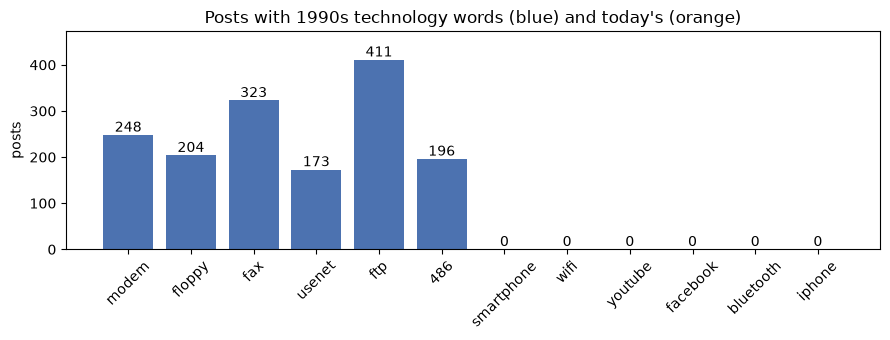

In [37]:
def posts_with_word(word):
    """Number of posts that contain the word as a whole word, in any case."""
    return df[TEXT_COL].str.contains(rf"\b{word}\b", case=False).sum()


old_words = ["modem", "floppy", "fax", "usenet", "ftp", "486"]
new_words = ["smartphone", "wifi", "youtube", "facebook", "bluetooth", "iphone"]
tech_word_posts = pd.Series({word: posts_with_word(word) for word in old_words + new_words})

plt.figure(figsize=(9, 3.5))
bars = plt.bar(tech_word_posts.index, tech_word_posts.values,
               color=["#4C72B0"] * len(old_words) + ["#DD8452"] * len(new_words))
plt.bar_label(bars)  # number of posts on top of each bar
plt.ylim(0, tech_word_posts.max() * 1.15)
plt.xticks(rotation=45)
plt.ylabel("posts")
plt.title("Posts with 1990s technology words (blue) and today's (orange)")
plt.tight_layout()
plt.show()

**Finding.** Each 1990s word appears in roughly 170 to 410 posts, while none of the modern words appears even once. A model trained on this data has never seen today's vocabulary: for a post about a smartphone it can only use the older words it knows. This is a limitation for the report and a good test case for the UI (T21) and the drift test (B10). The topics are dated as well: the posts discuss the events and products of the early 1990s.

## 9. Summary of the audit

### 9.1 Counts table

In [38]:
pd.Series(counts).to_frame("count")

,count
Rows in the raw file,18846
Empty posts,515
Exact duplicates (extra copies),69
Duplicates ignoring case and spacing (extra copies),78
Duplicated texts under different newsgroups,14
Posts with an e-mail address,2798
Posts with a URL or FTP host,121
Posts with X toolkit code,60
Posts with leftover reply quotes,181
Posts with encoded files,31


## 10. T4 decision: cleaning rules

Everything in this section follows from the findings above. T5 implements the rules in `src/newsclf/clean.py`; the same decisions are written in `reports/cleaning_decisions.md`.

### 10.1 Decision per issue

| # | Issue | What the audit found | Decision |
|---|---|---|---|
| 1 | Empty posts | 515 posts (2.7%), all missing values; 0.6% to 5.4% per newsgroup | **Drop** |
| 2 | Duplicates | 69 exact extra copies, 78 when case and spacing are ignored | **Keep one copy** of each normalised text (lower case, single spaces) |
| 3 | Same text under different newsgroups | 14 texts: junk (`--`, `...`) and cross-posts | **Drop all copies**: there is no single correct label |
| 4 | Very short posts | 187 posts with fewer than 5 words; 1-2 word posts carry no topic, 3-4 word posts sometimes do | **Drop posts with fewer than 3 words**, counted after cleaning |
| 5 | Very long posts | 150 posts with more than 2,000 words: FAQs and long documents, full of topic words | **Keep**, no upper limit; transformers truncate to their maximum length (T10, T11) |
| 6 | E-mail addresses | 2,798 posts (15%); repeated addresses identify the author | **Replace** with the token `emailaddress` |
| 7 | URLs | 121 posts | **Replace** with the token `urladdress` (after the e-mail addresses) |
| 8 | Numbers | Often topic words (486, 610, 1914) | **Keep** |
| 9 | Code snippets | Concentrated in the comp groups (all X toolkit code in comp.windows.x) | **Keep** |
| 10 | Reply quotes | 181 posts with lines starting with `>` | **Remove these lines** |
| 11 | Encoded files | 31 posts, 15,397 lines of random characters | **Remove these lines** |
| 12 | Separator lines, ASCII art | 2,170 posts; no words | **Remove these lines** (lines without any letter or digit) |
| 13 | Upper/lower case, punctuation | The TF-IDF tokenizer lower-cases and drops punctuation itself (6.4) | **No change** in the cleaned text |
| 14 | Stop words, stemming | Not a data problem | **Not part of cleaning**: stop words are a TF-IDF setting to try in tuning (T13); no stemming, so the text stays readable for the UI and the transformers |
| 15 | Non-ASCII characters, typos | 25 posts with non-ASCII characters; typos rare and not systematic | **No action** |

### 10.2 Order of the steps in T5

1. Drop empty posts (missing, or only spaces and line breaks).
2. In each post, remove the reply-quote lines, the encoded-file lines and the separator lines.
3. Replace e-mail addresses with `emailaddress`, then URLs with `urladdress`.
4. Turn every run of spaces and line breaks into a single space and strip both ends.
5. Count the words again and drop posts with fewer than 3 words. This also drops posts that consisted only of quotes or encoded lines.
6. Build the normalised text (lower case). Drop all copies of texts that appear under more than one newsgroup, then keep the first copy of every remaining text.
7. Save `post_id`, the cleaned `text`, `newsgroup` and `topic_group` to `data/processed/clean.csv`.

### 10.3 Rules for the later tasks (not part of the cleaning)

- **Split after cleaning (T6):** stratified by `newsgroup` (this also stratifies `topic_group`, see 2.1), fixed seed 42, the same split for every model.
- **TF-IDF on the training data only:** apart from the duplicate check, which must happen before the split on purpose, the cleaning rules look at one post at a time and learn nothing from the data set. Applying them before the split is therefore safe. TF-IDF is different: it learns the vocabulary and the IDF weights from the data. `TfidfVectorizer` and the classifier go into one scikit-learn `Pipeline`, so the vectorizer is fitted on the training data (or the training folds in cross-validation) only (T8, T9, T13).
- **Unbalanced topic groups:** report macro-F1 next to accuracy and try `class_weight="balanced"` for the 6-class task, because `forsale` is only about 5% of the posts.
- **Close newsgroups:** expect confusions inside comp, politics and religion (20 classes), and between sci.electronics and comp and between talk.politics.misc and religion (6 classes). Check them in the error analysis (T15).
- **Near-duplicates** such as the three JPEG FAQ versions are not removed by the exact duplicate check; bonus task B5 measures their effect.
- **Dated vocabulary:** mention the 1990s text as a limitation in the report and test the UI with modern posts (T21, B10).